# Cleaning & EDA — Data Kunjungan Klinik 2025

**Sumber data:** `DATA_KUNJUNGAN_2025_ANONIMASI.xlsx` (sheet `Dataset_Kunjungan_2025`, sudah ter-anonimasi)

**Tujuan notebook:**
1. Cleaning & validasi data kunjungan tahun 2025
2. EDA struktur data (layanan, sesi, umur, diagnosa)
3. EDA time-series (trend, pola harian/mingguan/bulanan)
4. Pattern finding sebagai insight untuk model prediksi

**Target pemodelan (notebook berikutnya):** data level **harian** — model belajar dari kunjungan harian per layanan, hasil prediksinya **7 hari ke depan sekaligus** (premium seminggu).

**Keluaran notebook ini:** `data_harian_kunjungan_2025.csv` (tabel harian per layanan + fitur kalender) siap dipakai tahap modeling.

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 100

NAMA_HARI = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
HARI_MAP = dict(enumerate(NAMA_HARI))

## 1. Load Data

In [ ]:
FILE = 'Dataset/DATA_KUNJUNGAN_2025_ANONIMASI.xlsx'
df_raw = pd.read_excel(FILE, sheet_name='Dataset_Kunjungan_2025')
print('Dimensi:', df_raw.shape)
df_raw.head()

Dimensi: (1239, 8)


,Id_Kunjungan,Id_Pasien,Tanggal,Sesi,Umur,Layanan,Diagnosa,Terapi / Tindakan
0,K0001,P0001,2025-01-01,Sesi 1,12 tahun,Berobat,GEA,"Lecozine, Vaseperum, PP"
1,K0002,P0002,2025-01-01,Sesi 2,41 tahun,KB,Akseptor KB suntik 2 bulan,F2
2,K0003,P0003,2025-01-02,Sesi 1,29 tahun,Ibu hamil,G1P0A0 Hamil 28 minggu,"FE, Calcifar, TT"
3,K0004,P0004,2025-01-02,Sesi 1,28 tahun,USG,G1P0A0 Hamil 21 minggu,USG
4,K0005,P0005,2025-01-02,Sesi 2,29 tahun,Berobat,Hipertensi,"Nifedipine, Neurodex"


In [3]:
df_raw["Layanan"].unique()

array(['Berobat', 'KB', 'Ibu hamil', 'USG', 'Program kehamilan',
       'Imunisasi', 'Pijat bayi', 'Ibu bersalin'], dtype=object)

## 2. Audit Kualitas Data

In [3]:
print('Rentang tanggal :', df_raw.Tanggal.min().date(), 'sampai', df_raw.Tanggal.max().date())
print('Hari unik       :', df_raw.Tanggal.nunique())
print()
print('Tipe data:')
print(df_raw.dtypes)
print()
print('Missing per kolom:')
print(df_raw.isna().sum())
print()
print('Duplikat Id_Kunjungan :', df_raw.Id_Kunjungan.duplicated().sum())
print('Duplikat baris penuh  :', df_raw.duplicated().sum())

Rentang tanggal : 2025-01-01 sampai 2025-12-31
Hari unik       : 350

Tipe data:
Id_Kunjungan                 object
Id_Pasien                    object
Tanggal              datetime64[ns]
Sesi                         object
Umur                         object
Layanan                      object
Diagnosa                     object
Terapi / Tindakan            object
dtype: object

Missing per kolom:
Id_Kunjungan         0
Id_Pasien            0
Tanggal              0
Sesi                 0
Umur                 0
Layanan              0
Diagnosa             0
Terapi / Tindakan    0
dtype: int64

Duplikat Id_Kunjungan : 0
Duplikat baris penuh  : 0


In [4]:
for col in ['Sesi', 'Layanan', 'Umur']:
    print(f'--- {col} ---')
    print(df_raw[col].value_counts())
    print()
print('Jumlah unik Diagnosa         :', df_raw.Diagnosa.nunique())
print('Jumlah unik Terapi/Tindakan  :', df_raw['Terapi / Tindakan'].nunique())
print('Pasien unik                  :', df_raw.Id_Pasien.nunique())

--- Sesi ---
Sesi
Sesi 2                 766
Sesi 1                 447
Khusus (Persalinan)     26
Name: count, dtype: int64

--- Layanan ---
Layanan
KB                   357
Berobat              312
Ibu hamil            258
Imunisasi            173
USG                   54
Pijat bayi            36
Ibu bersalin          26
Program kehamilan     23
Name: count, dtype: int64

--- Umur ---
Umur
41 tahun    82
23 tahun    76
28 tahun    71
31 tahun    58
35 tahun    55
1 bulan     53
34 tahun    50
27 tahun    50
30 tahun    49
40 tahun    48
42 tahun    47
33 tahun    45
3 bulan     44
39 tahun    42
2 bulan     42
38 tahun    39
25 tahun    38
29 tahun    34
26 tahun    31
4 bulan     28
36 tahun    27
22 tahun    25
24 tahun    20
8 bulan     16
32 tahun    15
37 tahun    13
8 tahun     13
9 tahun     13
9 bulan     11
7 tahun     10
3 tahun     10
13 tahun     7
4 tahun      6
11 tahun     6
10 tahun     6
45 tahun     5
12 tahun     5
2 tahun      5
5 tahun      4
6 tahun      4
5 bul

**Temuan audit:**
- Satu baris = satu kunjungan (pasien bisa muncul berkali-kali, normal untuk data clinic visit).
- Tidak ada missing value & tidak ada duplikat.
- `Umur` berbentuk teks dua satuan: **"X tahun"** dan **"X bulan"** (bayi/pijat bayi) → perlu dinormalisasi.
- `Diagnosa` mencampur beberapa makna: nama penyakit (GEA, Ispa, Hipertensi...), strategi KB ("Akseptor KB suntik 1 bulan"...), status kehamilan ("G1P0A0 Hamil 28 minggu"), kode administratif (MCU, Non-Diagnostik) → perlu dipetakan ke `sub_layanan`.
- `Sesi` = 2 sesi reguler + sesi khusus persalinan → persalinan adalah layanan event, bukan jadwal reguler.

Hasilnya: data sudah sangat bersih, cleaning berfokus ke **transformasi fitur**, bukan perbaikan error.

## 3. Cleaning & Rekayasa Fitur

### 3.1 Parsing `Umur` → angka + kategori

In [5]:
df = df_raw.copy()

umur = df.Umur.str.extract(r'^\s*(\d+)\s*(\w+)\s*$')
df['umur_angka'] = pd.to_numeric(umur[0], errors='coerce')
df['satuan_umur'] = umur[1].str.lower()
df['umur_tahun'] = np.where(df.satuan_umur.eq('bulan'), df.umur_angka / 12, df.umur_angka)

bins = [-0.1, 1, 5, 11, 17, 59, 200]
labels = ['Bayi (<1 th)', 'Balita (1-5 th)', 'Anak (6-11 th)', 'Remaja (12-17 th)',
          'Dewasa (18-59 th)', 'Lansia (60+ th)']
df['kategori_umur'] = pd.cut(df.umur_tahun, bins=bins, labels=labels)

print('Gagal parsing umur :', df.umur_tahun.isna().sum())
print('Rentang umur       :', df.umur_tahun.min(), 'sampai', df.umur_tahun.max(), 'tahun')
df[['Umur', 'umur_tahun', 'kategori_umur']].drop_duplicates(subset='Umur').head(12)

Gagal parsing umur : 0
Rentang umur       : 0.0 sampai 53.0 tahun


,Umur,umur_tahun,kategori_umur
0,12 tahun,12.000000,Remaja (12-17 th)
1,41 tahun,41.000000,Dewasa (18-59 th)
2,29 tahun,29.000000,Dewasa (18-59 th)
3,28 tahun,28.000000,Dewasa (18-59 th)
5,31 tahun,31.000000,Dewasa (18-59 th)
6,35 tahun,35.000000,Dewasa (18-59 th)
8,39 tahun,39.000000,Dewasa (18-59 th)
13,4 tahun,4.000000,Balita (1-5 th)
15,1 bulan,0.083333,Bayi (<1 th)
16,2 tahun,2.000000,Balita (1-5 th)


### 3.2 `Diagnosa` → `sub_layanan` (detail layanan)

Kelompokkan 61 jenis diagnosa menjadi kategori yang bisa dieksplorasi:

In [6]:
def kategori_detail(diag):
    d = str(diag)
    dl = d.lower()
    if d.startswith('Akseptor KB'):
        if 'suntik 1 bulan' in dl:
            return 'KB Suntik 1 bln'
        if 'suntik 2 bulan' in dl:
            return 'KB Suntik 2 bln'
        if 'suntik 3 bulan' in dl:
            return 'KB Suntik 3 bln'
        if 'pil' in dl:
            return 'KB Pil'
        return 'KB Lain'
    if 'inpartu' in dl:
        return 'Persalinan (inpartu)'
    if 'Hamil' in d:
        return 'ANC/USG Hamil'
    if d == 'Non-Diagnostik':
        return 'Pijat Bayi'
    return d

df['sub_layanan'] = df.Diagnosa.map(kategori_detail)
pd.crosstab(df.Layanan, df.sub_layanan)

sub_layanan,ANC/USG Hamil,Asam urat,Asma,Bapil,Febris,GEA,Gastritis,Hipertensi,Hipertermi,Imunisasi,...,KB Suntik 3 bln,Konjungtivitis,MCU,Persalinan (inpartu),Pijat Bayi,Promil,Tonsilitis,Urtikaria,Vertigo,Vomitus
Layanan,,,,,,,,,,,,,,,,,,,,,
Berobat,0,24,26,11,32,9,22,37,14,0,...,0,11,28,0,0,0,9,20,19,9
Ibu bersalin,0,0,0,0,0,0,0,0,0,0,...,0,0,0,26,0,0,0,0,0,0
Ibu hamil,258,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Imunisasi,0,0,0,0,0,0,0,0,0,173,...,0,0,0,0,0,0,0,0,0,0
KB,0,0,0,0,0,0,0,0,0,0,...,57,0,0,0,0,0,0,0,0,0
Pijat bayi,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,36,0,0,0,0,0
Program kehamilan,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,23,0,0,0,0
USG,54,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### 3.3 Fitur kalender & validasi akhir

In [7]:
df.Tanggal = pd.to_datetime(df.Tanggal)

assert df.Id_Kunjungan.is_unique, 'ada Id_Kunjungan duplikat!'
assert df.Tanggal.isna().sum() == 0
assert df.Tanggal.dt.year.eq(2025).all(), 'ada tanggal di luar 2025!'

df['dow'] = df.Tanggal.dt.dayofweek
df['nama_hari'] = df.dow.map(HARI_MAP)
df['minggu_start'] = (df.Tanggal - pd.to_timedelta(df.dow, unit='D')).dt.normalize()
df['minggu_ke'] = ((df.Tanggal - df.Tanggal.min()).dt.days // 7).astype(int)
df['bulan'] = df.Tanggal.dt.month
df['nama_bulan'] = df.Tanggal.dt.strftime('%b')
df['kuartal'] = df.Tanggal.dt.quarter

df = df.sort_values('Tanggal').reset_index(drop=True)
print('Baris data bersih:', len(df))
print('Rentang hari aktif:', df.Tanggal.nunique(), 'hari dari', df_raw.Tanggal.nunique(), 'hari')
df.head(3)

Baris data bersih: 1239
Rentang hari aktif: 350 hari dari 350 hari


,Id_Kunjungan,Id_Pasien,Tanggal,Sesi,Umur,Layanan,Diagnosa,Terapi / Tindakan,umur_angka,satuan_umur,umur_tahun,kategori_umur,sub_layanan,dow,nama_hari,minggu_start,minggu_ke,bulan,nama_bulan,kuartal
0,K0001,P0001,2025-01-01,Sesi 1,12 tahun,Berobat,GEA,"Lecozine, Vaseperum, PP",12,tahun,12.0,Remaja (12-17 th),GEA,2,Rabu,2024-12-30,0,1,Jan,1
1,K0002,P0002,2025-01-01,Sesi 2,41 tahun,KB,Akseptor KB suntik 2 bulan,F2,41,tahun,41.0,Dewasa (18-59 th),KB Suntik 2 bln,2,Rabu,2024-12-30,0,1,Jan,1
2,K0003,P0003,2025-01-02,Sesi 1,29 tahun,Ibu hamil,G1P0A0 Hamil 28 minggu,"FE, Calcifar, TT",29,tahun,29.0,Dewasa (18-59 th),ANC/USG Hamil,3,Kamis,2024-12-30,0,1,Jan,1


In [8]:
ORDER_LAYANAN = df.Layanan.value_counts().index.tolist()
print('Urutan layanan (besar -> kecil):')
for i, l in enumerate(ORDER_LAYANAN, 1):
    n = (df.Layanan == l).sum()
    print(f'{i}. {l:<20} {n:>5} ({n/len(df)*100:.1f}%)')

Urutan layanan (besar -> kecil):
1. KB                     357 (28.8%)
2. Berobat                312 (25.2%)
3. Ibu hamil              258 (20.8%)
4. Imunisasi              173 (14.0%)
5. USG                     54 (4.4%)
6. Pijat bayi              36 (2.9%)
7. Ibu bersalin            26 (2.1%)
8. Program kehamilan       23 (1.9%)


## 4. Basis Data Harian per Layanan

Grid lengkap = setiap tanggal aktif × semua layanan → hari tanpa kunjungan pada layanan tertentu diisi **0**. Tabel inilah yang nanti dipakai model.

In [9]:
LAYANAN = ORDER_LAYANAN
dates = pd.date_range(df.Tanggal.min(), df.Tanggal.max(), freq='D')
grid = pd.MultiIndex.from_product([dates, LAYANAN], names=['tanggal', 'layanan']).to_frame(index=False)

cnt = (df.groupby(['Tanggal', 'Layanan']).size()
         .rename('kunjungan').reset_index()
         .rename(columns={'Tanggal': 'tanggal', 'Layanan': 'layanan'}))

daily = grid.merge(cnt, on=['tanggal', 'layanan'], how='left').fillna({'kunjungan': 0})
daily['kunjungan'] = daily.kunjungan.astype(int)
daily['dow'] = daily.tanggal.dt.dayofweek
daily['nama_hari'] = daily.dow.map(HARI_MAP)
daily['minggu_start'] = (daily.tanggal - pd.to_timedelta(daily.dow, unit='D')).dt.normalize()
daily['bulan'] = daily.tanggal.dt.month
daily['is_weekend'] = daily.dow.ge(5).astype(int)

print('Grid harian:', daily.shape, '| kunjungan total:', daily.kunjungan.sum())
daily.head()

Grid harian: (2920, 8) | kunjungan total: 1239


,tanggal,layanan,kunjungan,dow,nama_hari,minggu_start,bulan,is_weekend
0,2025-01-01,KB,1,2,Rabu,2024-12-30,1,0
1,2025-01-01,Berobat,1,2,Rabu,2024-12-30,1,0
2,2025-01-01,Ibu hamil,0,2,Rabu,2024-12-30,1,0
3,2025-01-01,Imunisasi,0,2,Rabu,2024-12-30,1,0
4,2025-01-01,USG,0,2,Rabu,2024-12-30,1,0


## 5. EDA

### 5.1 Komposisi layanan & sesi

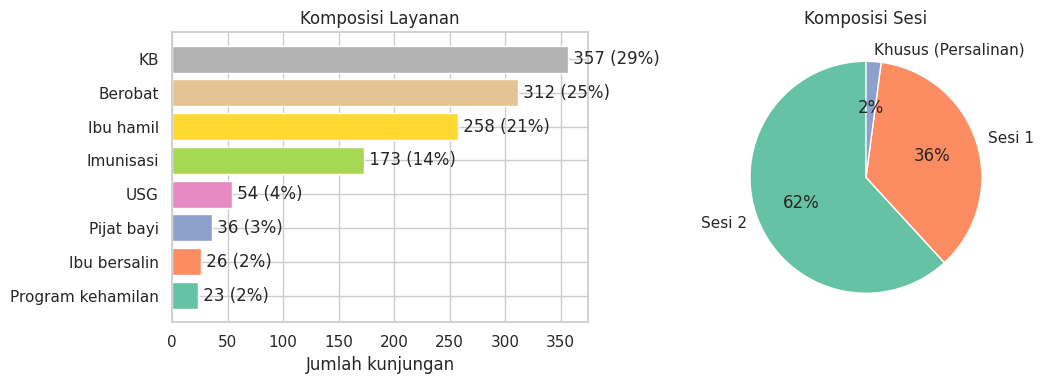

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

v = df.Layanan.value_counts()
axes[0].barh(v.index[::-1], v.values[::-1], color=sns.color_palette('Set2', len(v)))
for i, val in enumerate(v.values[::-1]):
    axes[0].text(val, i, f' {val} ({val/len(df)*100:.0f}%)', va='center')
axes[0].set_title('Komposisi Layanan')
axes[0].set_xlabel('Jumlah kunjungan')

s = df.Sesi.value_counts()
axes[1].pie(s.values, labels=s.index, autopct='%1.0f%%', startangle=90,
            colors=sns.color_palette('Set2', len(s)))
axes[1].set_title('Komposisi Sesi')

plt.tight_layout()
plt.show()

### 5.2 Umur pasien

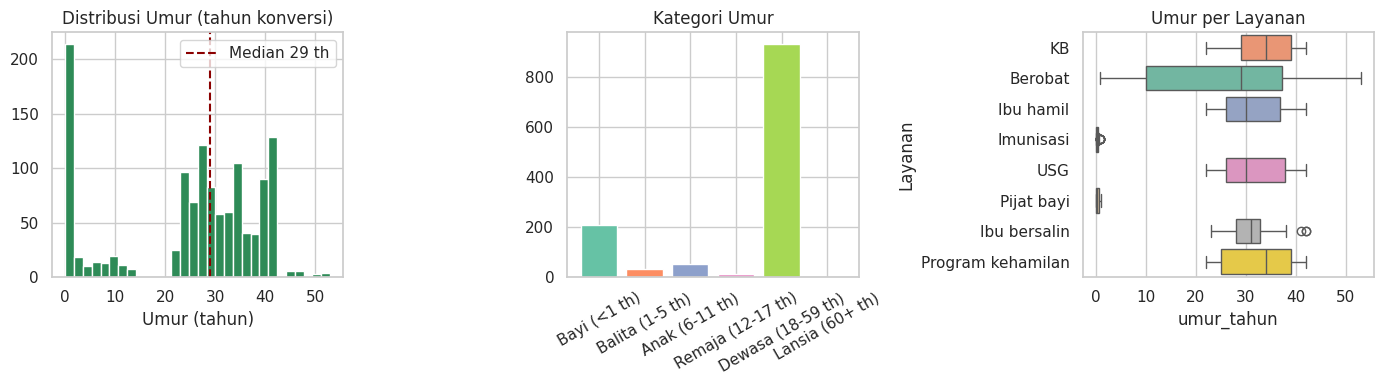

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(df.umur_tahun, bins=30, color='seagreen', edgecolor='white')
axes[0].axvline(df.umur_tahun.median(), color='darkred', ls='--',
                 label=f"Median {df.umur_tahun.median():.0f} th")
axes[0].set_title('Distribusi Umur (tahun konversi)')
axes[0].set_xlabel('Umur (tahun)')
axes[0].legend()

order_k = ['Bayi (<1 th)', 'Balita (1-5 th)', 'Anak (6-11 th)', 'Remaja (12-17 th)',
           'Dewasa (18-59 th)', 'Lansia (60+ th)']
vc = df.kategori_umur.value_counts().reindex(order_k)
axes[1].bar(vc.index, vc.values, color=sns.color_palette('Set2', len(vc)))
axes[1].set_title('Kategori Umur')
axes[1].tick_params(axis='x', rotation=30)

sns.boxplot(data=df, y='Layanan', x='umur_tahun', order=ORDER_LAYANAN, ax=axes[2],
            hue='Layanan', palette='Set2', legend=False)
axes[2].set_title('Umur per Layanan')

plt.tight_layout()
plt.show()

### 5.3 Top diagnosa / sub-layanan

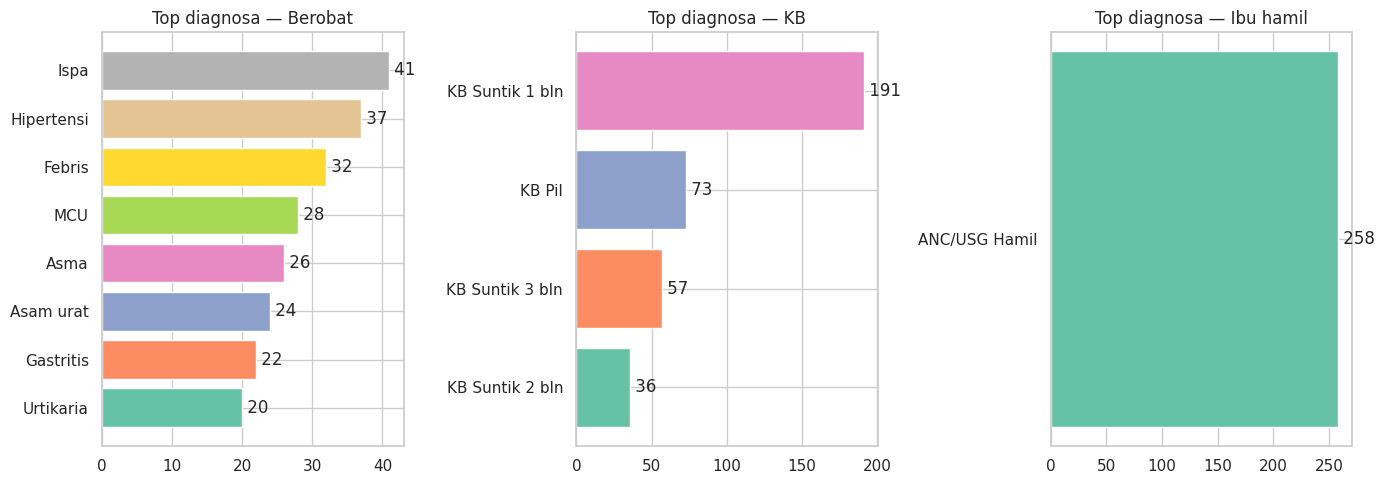

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, lay in zip(axes, ['Berobat', 'KB', 'Ibu hamil']):
    topx = df[df.Layanan == lay].sub_layanan.value_counts().head(8)
    ax.barh(topx.index[::-1], topx.values[::-1], color=sns.color_palette('Set2', 8))
    for i, val in enumerate(topx.values[::-1]):
        ax.text(val, i, f' {val}', va='center')
    ax.set_title(f'Top diagnosa — {lay}')
plt.tight_layout()
plt.show()

### 5.4 Trend harian & mingguan

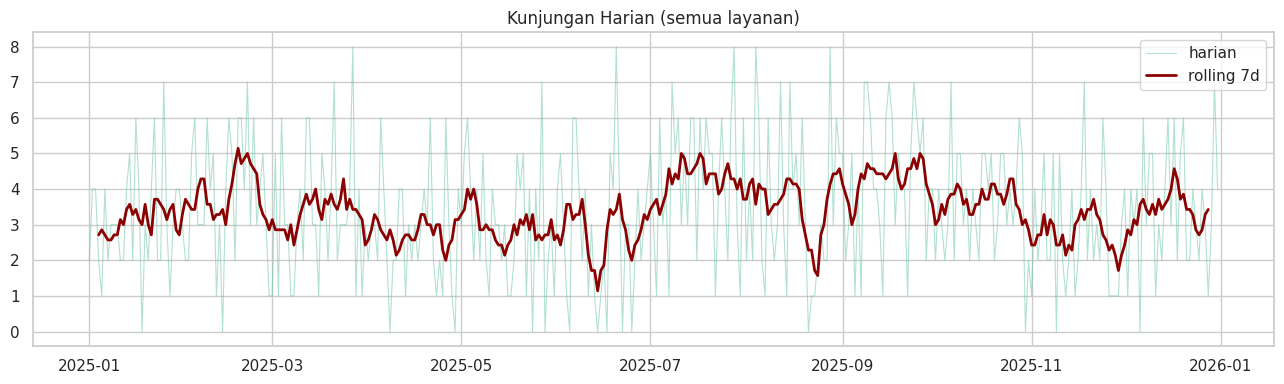

In [13]:
tot = daily.groupby('tanggal').kunjungan.sum()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(tot.index, tot.values, lw=0.8, alpha=0.5, label='harian')
ax.plot(tot.index, tot.rolling(7, center=True).mean(), lw=2, color='darkred', label='rolling 7d')
ax.set_title('Kunjungan Harian (semua layanan)')
ax.legend()
plt.tight_layout()
plt.show()

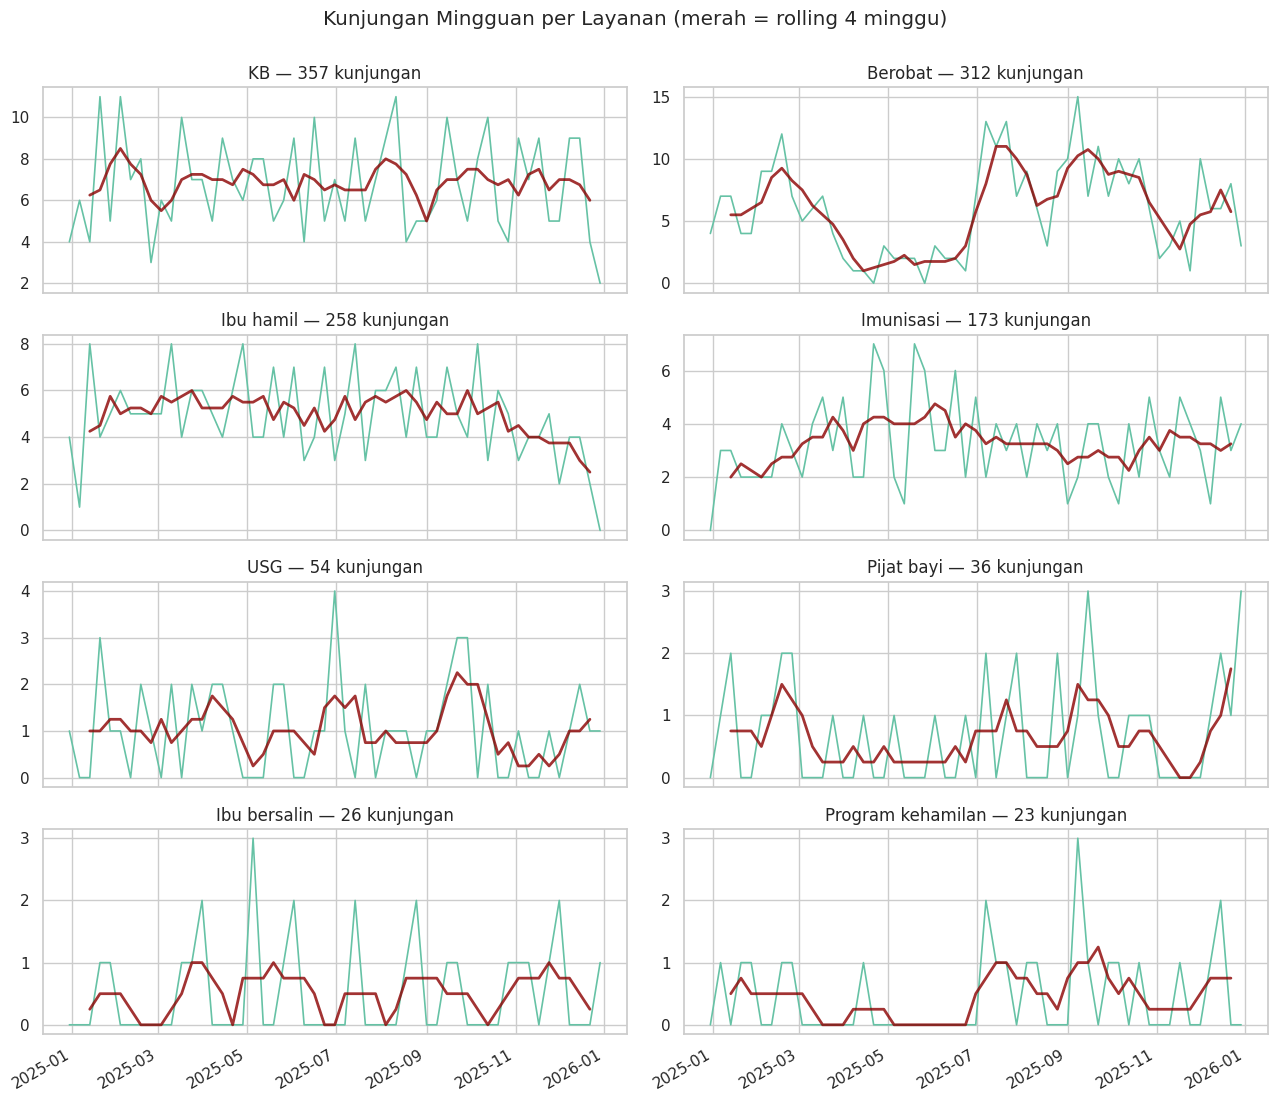

In [14]:
weekly = daily.groupby(['minggu_start', 'layanan']).kunjungan.sum().reset_index()

fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True)
for ax, lay in zip(axes.flat, ORDER_LAYANAN):
    sub = weekly[weekly.layanan == lay]
    ax.plot(sub.minggu_start, sub.kunjungan, lw=1.2)
    sub_m = sub.kunjungan.rolling(4, center=True).mean()
    ax.plot(sub.minggu_start, sub_m, lw=2, color='darkred', alpha=.8)
    ax.set_title(f'{lay} — {df.Layanan.value_counts()[lay]} kunjungan')
fig.suptitle('Kunjungan Mingguan per Layanan (merah = rolling 4 minggu)', y=1.0)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 5.5 Trend bulanan

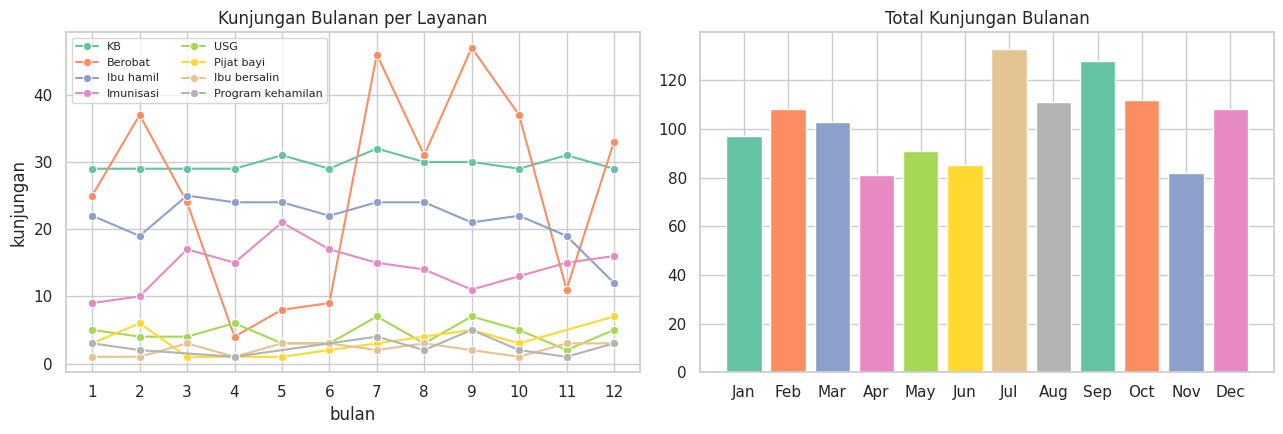

In [15]:
b = df.groupby(['bulan', 'Layanan']).size().rename('kunjungan').reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=b, x='bulan', y='kunjungan', hue='Layanan', hue_order=ORDER_LAYANAN,
             marker='o', ax=axes[0])
axes[0].set_xticks(range(1, 13))
axes[0].set_title('Kunjungan Bulanan per Layanan')
axes[0].legend(fontsize=8, ncol=2)

totb = b.groupby('bulan').kunjungan.sum()
axes[1].bar([pd.to_datetime(f'2025-{m:02d}-01').strftime('%b') for m in totb.index], totb.values,
            color=sns.color_palette('Set2', 12))
axes[1].set_title('Total Kunjungan Bulanan')

plt.tight_layout()
plt.show()

### 5.6 Pola hari dalam seminggu

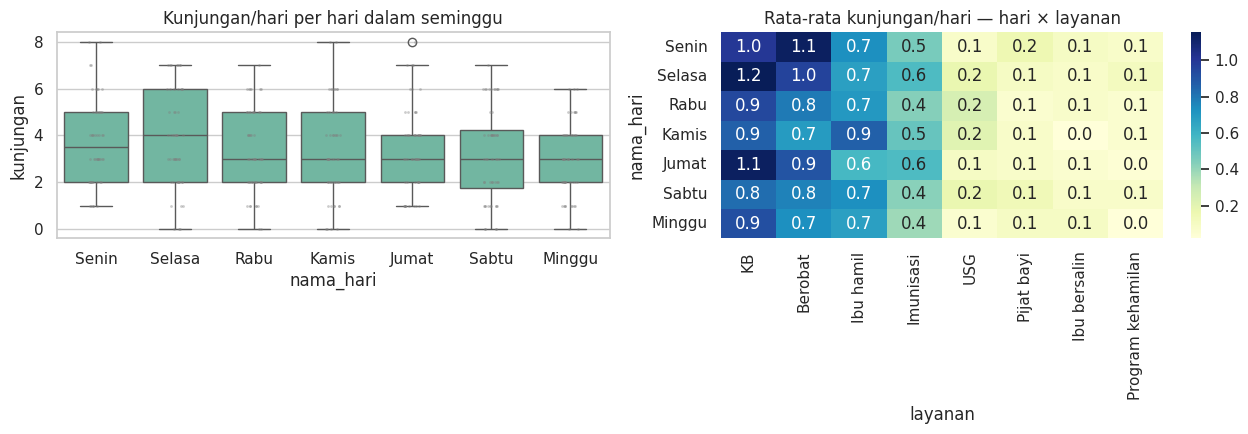

In [16]:
tot_hari = daily.groupby(['tanggal', 'nama_hari', 'dow'], as_index=False).kunjungan.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=tot_hari, x='nama_hari', y='kunjungan', order=NAMA_HARI, ax=axes[0])
sns.stripplot(data=tot_hari, x='nama_hari', y='kunjungan', order=NAMA_HARI, ax=axes[0],
              size=2, color='gray', alpha=.4)
axes[0].set_title('Kunjungan/hari per hari dalam seminggu')

hm = daily.pivot_table(index='nama_hari', columns='layanan', values='kunjungan',
                       aggfunc='mean').reindex(NAMA_HARI)[ORDER_LAYANAN]
sns.heatmap(hm, annot=True, fmt='.1f', cmap='YlGnBu', ax=axes[1])
axes[1].set_title('Rata-rata kunjungan/hari — hari × layanan')

plt.tight_layout()
plt.show()

### 5.7 Sesi & relasi layanan

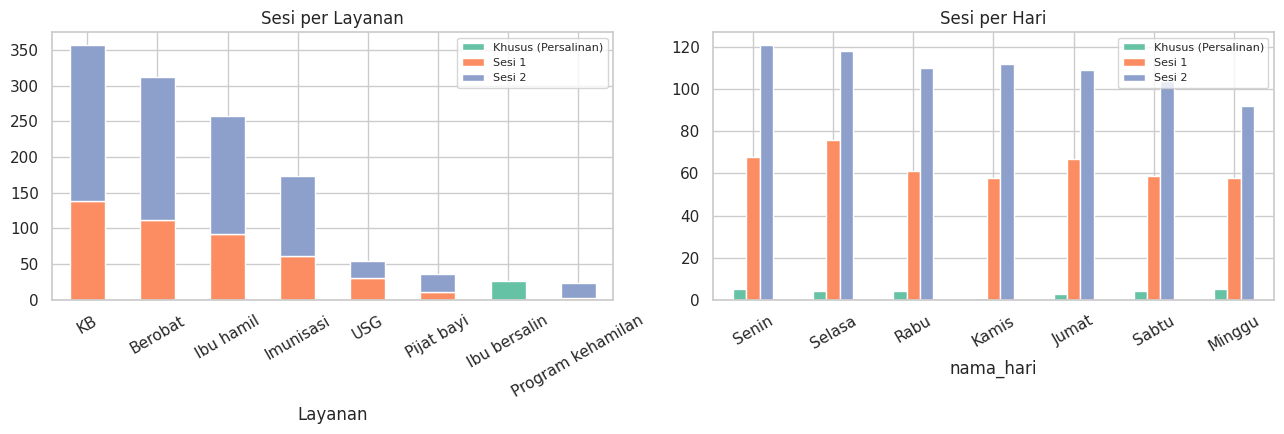

Crosstab Layanan × Sesi:


Sesi,Khusus (Persalinan),Sesi 1,Sesi 2
Layanan,,,
KB,0,138,219
Berobat,0,112,200
Ibu hamil,0,92,166
Imunisasi,0,61,112
USG,0,30,24
Pijat bayi,0,11,25
Ibu bersalin,26,0,0
Program kehamilan,0,3,20


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ct = pd.crosstab(df.Layanan, df.Sesi).reindex(ORDER_LAYANAN)
ct.plot(kind='bar', stacked=True, color=sns.color_palette('Set2', ct.shape[1]), ax=axes[0])
axes[0].set_title('Sesi per Layanan')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(fontsize=8)

sesi_hari = pd.crosstab(df.nama_hari, df.Sesi).reindex(NAMA_HARI)
sesi_hari.plot(kind='bar', color=sns.color_palette('Set2', sesi_hari.shape[1]), ax=axes[1])
axes[1].set_title('Sesi per Hari')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print('Crosstab Layanan × Sesi:')
ct

### 5.8 Pasien baru vs pasien lama

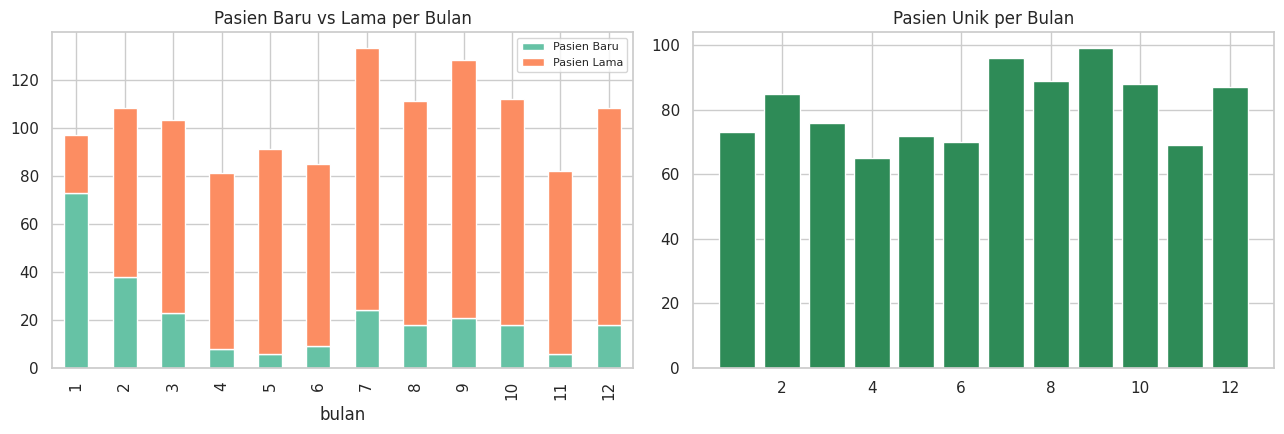

Pasien unik            : 262
Rata-rata kunjungan/pasien: 4.7
Proporsi kunjungan     : {'Pasien Lama': 0.79, 'Pasien Baru': 0.21}


In [18]:
df['kunjungan_ke'] = df.groupby('Id_Pasien').cumcount() + 1
df['tipe_kunjungan'] = np.where(df.kunjungan_ke.eq(1), 'Pasien Baru', 'Pasien Lama')

tipe_bulan = df.groupby(['bulan', 'tipe_kunjungan']).size().unstack(fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
tipe_bulan.plot(kind='bar', stacked=True, color=sns.color_palette('Set2', 2), ax=axes[0])
axes[0].set_title('Pasien Baru vs Lama per Bulan')
axes[0].set_xlabel('bulan')
axes[0].legend(fontsize=8)

pasien_bulan = df.groupby('bulan').Id_Pasien.nunique()
axes[1].bar(pasien_bulan.index, pasien_bulan.values, color='seagreen')
axes[1].set_title('Pasien Unik per Bulan')

plt.tight_layout()
plt.show()

repeat = df.tipe_kunjungan.value_counts(normalize=True)
print(f"Pasien unik            : {df.Id_Pasien.nunique()}")
print(f"Rata-rata kunjungan/pasien: {len(df)/df.Id_Pasien.nunique():.1f}")
print(f"Proporsi kunjungan     : {repeat.round(2).to_dict()}")


## 6. Pattern Finding untuk Model (Prediksi 7 Hari ke Depan)

Pertanyaan utama yang harus terjawab sebelum modeling:
1. Apakah kunjungan punya **pola hari dalam seminggu** yang konsisten? → fitur `dow` wajib
2. Apakah ada **lag** yang kuat (mis. korelasi dengan hari yang sama minggu lalu)? → fitur lag mingguan
3. Apakah layanan saling **bergerak bersama** pada hari yang sama? → perlu multi-output
4. Apakah tiap layanan punya "hari operasional" tersendiri?

### 6.1 Frekuensi layanan aktif per hari

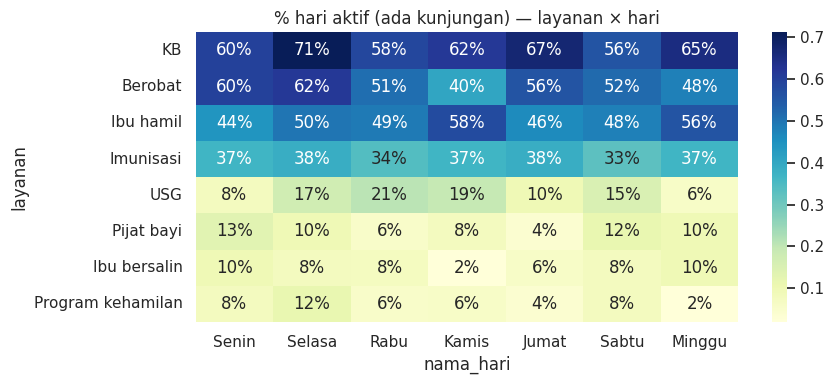

,layanan,nama_hari,frek_aktif,rata_saat_aktif,rata_semua_hari
6,Berobat,Senin,0.596154,1.903226,1.134615
5,Berobat,Selasa,0.615385,1.562500,0.961538
3,Berobat,Rabu,0.509434,1.555556,0.792453
1,Berobat,Kamis,0.403846,1.714286,0.692308
0,Berobat,Jumat,0.557692,1.620690,0.903846
4,Berobat,Sabtu,0.519231,1.481481,0.769231
2,Berobat,Minggu,0.480769,1.520000,0.730769
13,Ibu bersalin,Senin,0.096154,1.000000,0.096154
12,Ibu bersalin,Selasa,0.076923,1.000000,0.076923
10,Ibu bersalin,Rabu,0.075472,1.000000,0.075472


In [19]:
aktif = daily.groupby(['layanan', 'nama_hari']).agg(
    frek_aktif=('kunjungan', lambda s: (s > 0).mean()),
    rata_saat_aktif=('kunjungan', lambda s: s[s > 0].mean()),
    rata_semua_hari=('kunjungan', 'mean')
).reset_index()

hhm = aktif.pivot(index='layanan', columns='nama_hari',
                  values='frek_aktif').reindex(ORDER_LAYANAN)[NAMA_HARI]
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(hhm, annot=True, fmt='.0%', cmap='YlGnBu', ax=ax)
ax.set_title('% hari aktif (ada kunjungan) — layanan × hari')
plt.tight_layout()
plt.show()

aktif['urutan'] = aktif.nama_hari.map({h: i for i, h in enumerate(NAMA_HARI)})
aktif.sort_values(['layanan', 'urutan']).drop(columns='urutan')

### 6.2 Autokorelasi (apakah kemarin / minggu lalu menentukan hari ini?)

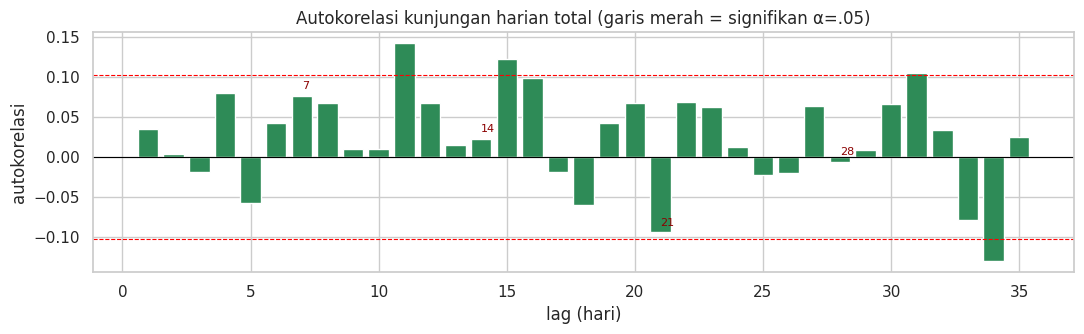

Lag dengan autokorelasi tertinggi (total):
11    0.142
15    0.122
31    0.104
16    0.098
4     0.080
dtype: float64


In [20]:
series = daily.groupby('tanggal').kunjungan.sum()

lags = range(1, 36)
acf_v = [series.autocorr(l) for l in lags]
sig = 1.96 / np.sqrt(len(series))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(list(lags), acf_v, color='seagreen')
ax.axhline(0, color='black', lw=0.8)
for y in (sig, -sig):
    ax.axhline(y, color='red', ls='--', lw=0.8)
for l_ in [7, 14, 21, 28]:
    ax.annotate(str(l_), (l_, acf_v[list(lags).index(l_)]),
                textcoords='offset points', xytext=(0, 5), fontsize=8, color='darkred')
ax.set_xlabel('lag (hari)')
ax.set_ylabel('autokorelasi')
ax.set_title('Autokorelasi kunjungan harian total (garis merah = signifikan α=.05)')
plt.tight_layout()
plt.show()

top3 = pd.Series(acf_v, index=list(lags)).sort_values(ascending=False).head(5)
print('Lag dengan autokorelasi tertinggi (total):')
print(top3.round(3))

In [21]:
rows = []
for lay in ORDER_LAYANAN:
    s = daily[daily.layanan == lay].sort_values('tanggal').set_index('tanggal').kunjungan
    acf = {l: s.autocorr(l) for l in [1, 2, 3, 5, 6, 7, 14, 21, 28]}
    best = max(acf, key=acf.get)
    rows.append({'layanan': lay, **{f'lag_{l}': round(v, 2) for l, v in acf.items()},
                 'lag_terbaik': best, 'acf_terbaik': round(acf[best], 2)})
pa = pd.DataFrame(rows).set_index('layanan')
pa

,lag_1,lag_2,lag_3,lag_5,lag_6,lag_7,lag_14,lag_21,lag_28,lag_terbaik,acf_terbaik
layanan,,,,,,,,,,,
KB,-0.16,0.00,-0.11,-0.02,-0.03,-0.01,0.06,-0.16,-0.01,14,0.06
Berobat,0.17,0.12,0.22,0.12,0.16,0.20,0.07,-0.05,0.08,3,0.22
Ibu hamil,-0.13,-0.04,-0.12,-0.09,0.06,-0.01,0.01,-0.03,-0.06,6,0.06
Imunisasi,-0.04,0.06,-0.12,-0.09,-0.07,-0.07,-0.01,0.03,0.03,2,0.06
USG,0.02,-0.01,-0.07,0.04,-0.05,-0.01,0.00,0.03,-0.05,5,0.04
Pijat bayi,0.06,-0.04,-0.03,0.04,0.04,0.04,-0.00,-0.02,0.00,1,0.06
Ibu bersalin,-0.04,0.05,0.01,0.09,-0.03,0.01,-0.04,0.05,-0.08,5,0.09
Program kehamilan,0.03,0.03,0.03,-0.02,0.03,0.03,-0.02,-0.06,-0.01,6,0.03


### 6.3 Korelasi antar layanan (hari yang sama)

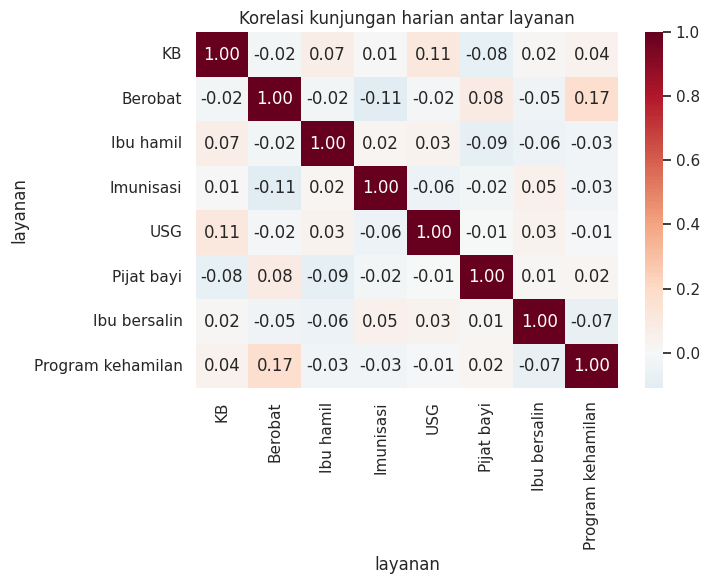

In [22]:
matriks = daily.pivot(index='tanggal', columns='layanan', values='kunjungan')
corr = matriks.corr()[ORDER_LAYANAN].reindex(ORDER_LAYANAN)

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Korelasi kunjungan harian antar layanan')
plt.tight_layout()
plt.show()

### 6.4 Uji beda antar-hari (Kruskal-Wallis)

In [23]:
rows = []
for lay in ORDER_LAYANAN:
    groups = [g.kunjungan.values for _, g in daily[daily.layanan == lay].groupby('nama_hari')]
    H, p = stats.kruskal(*groups)
    rows.append({'layanan': lay, 'H': round(H, 2), 'p_value': p,
                 'pola_hari_signifikan': p < 0.05})
pd.DataFrame(rows).set_index('layanan')

,H,p_value,pola_hari_signifikan
layanan,,,
KB,4.84,0.564150,False
Berobat,7.74,0.258065,False
Ibu hamil,2.85,0.827101,False
Imunisasi,1.38,0.966791,False
USG,9.62,0.141779,False
Pijat bayi,4.28,0.639398,False
Ibu bersalin,3.30,0.770086,False
Program kehamilan,5.02,0.540798,False


### 6.5 Ringkasan insight otomatis

In [24]:
tot_hari_mean = tot_hari.groupby('nama_hari').kunjungan.mean().reindex(NAMA_HARI)
h1 = df[df.bulan <= 6].Layanan.value_counts(normalize=True)
h2 = df[df.bulan > 6].Layanan.value_counts(normalize=True)

print('=' * 72)
print('RINGKASAN INSIGHT (untuk modeling)')
print('=' * 72)
print(f"1. Total {len(df)} kunjungan | {df.Id_Pasien.nunique()} pasien unik | {df.Tanggal.nunique()} hari aktif")
print(f"2. Hari teraktif : {tot_hari_mean.idxmax()} ({tot_hari_mean.max():.1f}/hari) | tersepi: {tot_hari_mean.idxmin()} ({tot_hari_mean.min():.1f}/hari)")
for i, lay in enumerate(ORDER_LAYANAN, 3):
    share = (df.Layanan == lay).mean() * 100
    delta = (h2[lay] - h1[lay]) * 100
    print(f"{i}. {lay:<18} share {share:.0f}%  (sem1 -> sem2: {delta:+.1f} pct point)")
print('11. Layanan aktif 100% semua hari:',
      list(hhm.index[(hhm == 1).all(axis=1)]))

RINGKASAN INSIGHT (untuk modeling)
1. Total 1239 kunjungan | 262 pasien unik | 350 hari aktif
2. Hari teraktif : Selasa (3.8/hari) | tersepi: Minggu (3.0/hari)
3. KB                 share 29%  (sem1 -> sem2: -4.3 pct point)
4. Berobat            share 25%  (sem1 -> sem2: +11.5 pct point)
5. Ibu hamil          share 21%  (sem1 -> sem2: -6.0 pct point)
6. Imunisasi          share 14%  (sem1 -> sem2: -3.3 pct point)
7. USG                share 4%  (sem1 -> sem2: -0.1 pct point)
8. Pijat bayi         share 3%  (sem1 -> sem2: +0.8 pct point)
9. Ibu bersalin       share 2%  (sem1 -> sem2: -0.0 pct point)
10. Program kehamilan  share 2%  (sem1 -> sem2: +1.5 pct point)
11. Layanan aktif 100% semua hari: []


### 6.6 Insight utama (temuan riil dari data 2025)

**Struktur volume**
- Rata-rata hanya **3,4 kunjungan/hari** (std 1,9) – data harian bernilai kecil & menimbi Poisson-like: evaluasi model pakai MAE/MAPE hati-hati; pertimbangkan model per-orang-backend (GluonTS/Temporal) atau regresi + interval Poisson.
- Puncak volume: **Juli 133 kunjungan/bulan**, terendah April 81; minggu teraktif 2025-07-14 (35/minggu).
- Tiga layanan dominan: **KB 29%**, **Berobat 25%**, **Ibu hamil 21%** (mayoritas volume).

**Trend antar semester**
- **Berobat naik kuat** saat semester 2 (+11,5 pct point share).
- **KB (−4,3)**, **Ibu hamil (−6,0)**, **Imunisasi (−3,3)** menurun share.
- → Model harus memakai fitur trend/bulan, jangan mengasumsikan stasioner.

**Pola hari dalam seminggu**
- Deskriptif: Selasa teraktif (3,8/hari), Minggu tersepi (3,0/hari).
- Namun **uji Kruskal-Wallis tidak signifikan untuk semua layanan (p > 0,05)** → pola hari lemah; fitur  perlu tapi jangan mengharapkan kontribusi besar.
- Semua layanan hadir di semua hari (tidak ada hari operasional khusus), kecuali Ibu bersalin yang jarang (26/tahun, selalu **sesi khusus persalinan**).

**Dependensi temporal & antar layanan**
- Autokorelasi harian **sangat lemah** (maks 0,22 pada Berobat lag-3; lag-7/14 tidak menonjol) → kemarin/minggu lalu hampir tidak menentukan hari ini; fitur lag harian berguna terbatas → prediksi 7 hari ke depan sekaligus cocok langsung dari fitur kalender + level/trend per layanan.
- Korelasi antar layanan lemah (maks 0,17 Berobat × Program kehamilan) → tidak ada substitusi/kepatuhan kuat; model per-layanan terpisah cukup.

**Layanan langka**
- Ibu bersalin (26) & Program kehamilan (23) sangat jarang → untuk keduanya lebih tepat **prediksi Poisson/probabilitas per hari (y≥0/integer)** daripada regresi biasa.

**Komposisi KB (untuk sub-detail)**
- Suntik 1 bulan **54%**, Pil 20%, Suntik 3 bln 16%, Suntik 2 bln 10%.

**Perilaku pasien**
- 79% kunjungan = pasien lama; 262 pasien unik × rata2 4,7 kunjungan/pasien → alokasi pesan per pasien stabil, layanan jadwal-berulang (KB/ANC) menopang repeat rate tinggi.

**Saran untuk notebook modeling:** target = `kunjungan` dari `data_harian_kunjungan_2025.csv` per (tanggal, layanan); fitur utama: `dow`, `bulan` (one-hot/sin-cos), `minggu_ke` (trend), rolling-mean 4 minggu per layanan; horizon = 7 hari, evaluasi rolling-origin (hold out 4 minggu terakhir).

## 7. Ekspor Data untuk Modeling

In [25]:
daily.to_csv('data_harian_kunjungan_2025.csv', index=False)
df.to_csv('data_kunjungan_2025_bersih.csv', index=False)
print('data_harian_kunjungan_2025.csv   :', daily.shape)
print('data_kunjungan_2025_bersih.csv   :', df.shape)

data_harian_kunjungan_2025.csv   : (2920, 8)
data_kunjungan_2025_bersih.csv   : (1239, 22)
